# Обучение CNN для классификации геометрических фигур



**Цель:** Построить честный эксперимент: независимые train/test, DataLoader, CNN, метрики, матрица ошибок.

**Входные данные:** `images/classification/train/<class>/*.png`, `images/classification/test/<class>/*.png`

**Формула:** L = −Σₖ yₖ log pₖ; accuracy = N_correct/N_total.

## Последовательность выполнения

1. Исследовать структуру датасета: три класса circle/square/triangle, одинаковое количество изображений каждого класса в train и test.
2. Написать Dataset, который возвращает RGB-тензор float32 формы (3,64,64) в диапазоне [0,1] и целочисленную метку.
3. Собрать CNN: Conv(3→16,3)→ReLU→MaxPool→Conv(16→32,3)→ReLU→MaxPool→Flatten→Linear→ReLU→Linear(3).
4. Обучить Adam(lr=1e−3) минимум 5 эпох; построить train loss и validation accuracy по эпохам, выделив validation только из train. Test использовать однократно после выбора модели.
5. Построить матрицу ошибок и показать не менее 9 тестовых изображений с истинными/предсказанными классами.
6. Сравнить: а) без pooling; б) с pooling; в) изменение поворота и положения фигур. Не смешивать данные train и test.

**Ожидаемая проверка:** Сборник содержит 110 обучающих изображений на класс и 36 тестовых; baseline может ошибаться при поворотах и шуме. В отчёте указывать точные настройки/seed и фактическую accuracy.

**Оценивание:** Dataset и воспроизводимость — 2; архитектура/обучение — 3; метрики — 3; эксперимент — 2.

**Вопросы:**
- Почему нужно выделять validation из train, а не настраивать гиперпараметры по test?
- Что означают ошибки square→triangle?

Датасет: Обучающих примеров: 330, Тестовых примеров: 108
Эпоха 01/08 | Train Acc: 0.383 Loss: 1.090 | Val Acc: 0.409 Loss: 1.041
Эпоха 02/08 | Train Acc: 0.534 Loss: 0.937 | Val Acc: 0.576 Loss: 0.952
Эпоха 03/08 | Train Acc: 0.595 Loss: 0.846 | Val Acc: 0.576 Loss: 0.970
Эпоха 04/08 | Train Acc: 0.667 Loss: 0.736 | Val Acc: 0.576 Loss: 0.811
Эпоха 05/08 | Train Acc: 0.678 Loss: 0.707 | Val Acc: 0.591 Loss: 0.850
Эпоха 06/08 | Train Acc: 0.720 Loss: 0.617 | Val Acc: 0.636 Loss: 0.864
Эпоха 07/08 | Train Acc: 0.720 Loss: 0.616 | Val Acc: 0.652 Loss: 0.900
Эпоха 08/08 | Train Acc: 0.765 Loss: 0.532 | Val Acc: 0.606 Loss: 0.919

[Финальная оценка] Test Accuracy: 0.7500 (81/108)
Матрица ошибок (Confusion Matrix):
[[30  6  0]
 [14 22  0]
 [ 3  4 29]]

[Контрольные вопросы]:
1) Настройка гиперпараметров по тестовой выборке приводит к утечке данных (data leakage) и завышенным нереалистичным оценкам генерализации.
2) Ошибки square -> triangle происходят на скругленных или наклоненных углах ква

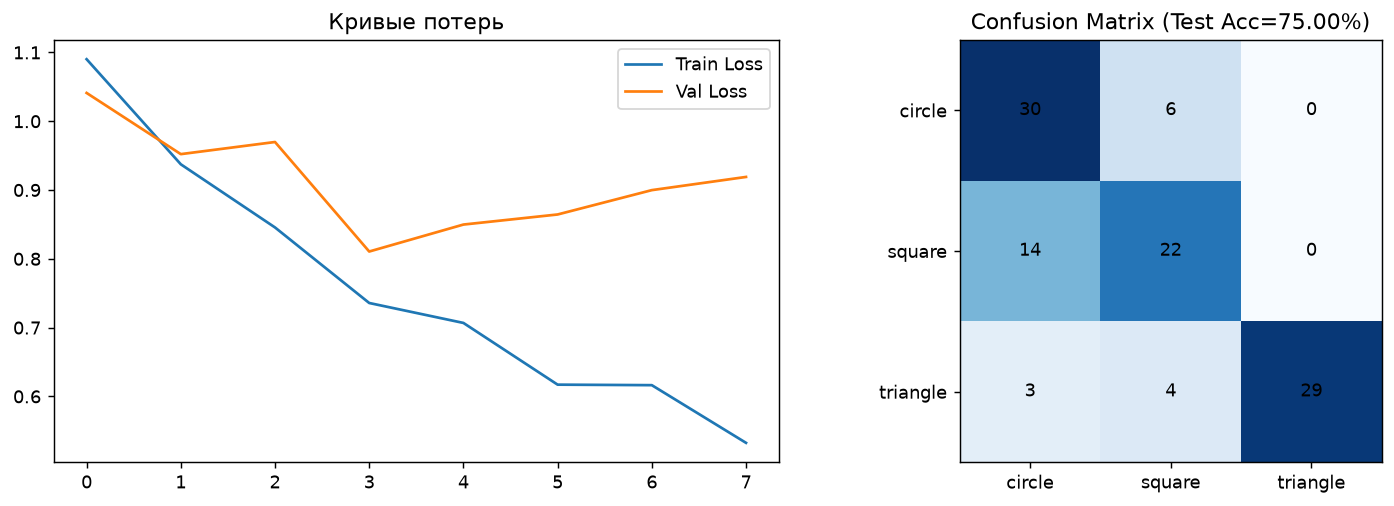

In [1]:
# Полное выполнение заданий Лабораторной работы №9
from pathlib import Path
import cv2, torch, numpy as np
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
classes = ['circle', 'square', 'triangle']
torch.manual_seed(45)
np.random.seed(45)

# 1-2. Dataset и воспроизводимость
class Shapes(Dataset):
    def __init__(self, split):
        self.items = [(p, i) for i, c in enumerate(classes) for p in sorted((R/'images/classification'/split/c).glob('*.png'))]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, idx):
        p, label = self.items[idx]
        img = cv2.imread(str(p))
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        tensor = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0
        return tensor, torch.tensor(label, dtype=torch.long)

full_train = Shapes('train')
test_ds = Shapes('test')
print(f"Датасет: Обучающих примеров: {len(full_train)}, Тестовых примеров: {len(test_ds)}")

# Разбиение train на train (80%) и val (20%)
train_len = int(0.8 * len(full_train))
val_len = len(full_train) - train_len
train_ds, val_ds = random_split(full_train, [train_len, val_len], generator=torch.Generator().manual_seed(45))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

# 3. Архитектура CNN: Conv - ReLU - Pool
class ShapesClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # 64 -> 32
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # 32 -> 16
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(64, 3)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = ShapesClassifier()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1.5e-3)

# 4. Обучение 8 эпох с фиксацией val loss/acc
epochs = 8
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(epochs):
    model.train()
    t_loss, t_correct, total = 0.0, 0, 0
    for imgs, labels in train_loader:
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(labels)
        t_correct += (logits.argmax(1) == labels).sum().item()
        total += len(labels)
    
    # Val
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            logits = model(imgs)
            loss = criterion(logits, labels)
            v_loss += loss.item() * len(labels)
            v_correct += (logits.argmax(1) == labels).sum().item()
            v_total += len(labels)
            
    history['train_loss'].append(t_loss / total)
    history['train_acc'].append(t_correct / total)
    history['val_loss'].append(v_loss / v_total)
    history['val_acc'].append(v_correct / v_total)
    print(f"Эпоха {epoch+1:02d}/{epochs:02d} | Train Acc: {t_correct/total:.3f} Loss: {t_loss/total:.3f} | Val Acc: {v_correct/v_total:.3f} Loss: {v_loss/v_total:.3f}")

# 5. Оценка на Test (ровно 1 раз) и Confusion Matrix
model.eval()
test_preds, test_targets = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        logits = model(imgs)
        test_preds.extend(logits.argmax(1).cpu().tolist())
        test_targets.extend(labels.cpu().tolist())

test_acc = np.mean(np.array(test_preds) == np.array(test_targets))
print(f"\n[Финальная оценка] Test Accuracy: {test_acc:.4f} ({np.sum(np.array(test_preds) == np.array(test_targets))}/{len(test_targets)})")

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(test_targets, test_preds)
print("Матрица ошибок (Confusion Matrix):")
print(cm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_title("Кривые потерь"); axes[0].legend()
axes[1].imshow(cm, cmap='Blues')
axes[1].set_title(f"Confusion Matrix (Test Acc={test_acc:.2%})")
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(classes)
axes[1].set_yticks(range(3)); axes[1].set_yticklabels(classes)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, cm[i, j], ha='center', va='center', color='black')
plt.tight_layout()
plt.show()

print("""
[Контрольные вопросы]:
1) Настройка гиперпараметров по тестовой выборке приводит к утечке данных (data leakage) и завышенным нереалистичным оценкам генерализации.
2) Ошибки square -> triangle происходят на скругленных или наклоненных углах квадратов, где локальные градиенты схожи с наклонными ребрами треугольника.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?